In [1]:
import sys
import pandas as pd
sys.path.insert(0, "..")
from backtest.db import connect, query_df

with connect() as conn:
    ModelData = query_df(conn, "select * from backtest.models")

ModelData.shape

(21562, 51)

In [2]:
ModelData['period_end'] = pd.to_datetime(ModelData['period_end'])
ModelData['rebalance_date'] = pd.to_datetime(ModelData['rebalance_date'])

# Growth is a property of each statement, so compute it on one row per
# (ticker, period_end), not on ModelData, which repeats a statement for ~12
# rebalance dates. temp_models also includes statements no rebalance date used.
with connect() as conn:
    statements = query_df(conn, """
        select ticker, period_end, revenue
        from backtest.temp_models
        where revenue > 0
    """)

statements['period_end'] = pd.to_datetime(statements['period_end'])
statements = statements.sort_values(['ticker', 'period_end'])
by_ticker = statements.groupby('ticker')

In [3]:
def cagr(k):
    """Revenue CAGR from the statement k years back: (Rev_T / Rev_{T-k})^(1/years) - 1."""
    years = (statements['period_end'] - by_ticker['period_end'].shift(k)).dt.days / 365.25
    return (statements['revenue'] / by_ticker['revenue'].shift(k)) ** (1 / years) - 1

statements['g0_raw'] = cagr(2).fillna(cagr(1))   # 2-year CAGR, else 1-year
statements['g0'] = statements['g0_raw'].clip(-0.10, 0.25)

#add the growth figs from the statements into the ModelData
ModelData = ModelData.drop(columns=['g0_raw', 'g0'], errors='ignore').merge(
    statements[['ticker', 'period_end', 'g0_raw', 'g0']],
    on=['ticker', 'period_end'], how='left')

In [4]:
statements[statements['ticker'] == 'AAPL'] #[['ticker', 'period_end', 'rebalance_date', 'g0']]

,ticker,period_end,revenue,g0_raw,g0
4,AAPL,2023-09-30,3.832850e+11,NaN,NaN
5,AAPL,2024-09-30,3.910350e+11,0.020178,0.020178
6,AAPL,2025-09-30,4.161610e+11,0.041976,0.041976
7,AAPL,2026-09-30,4.788340e+11,0.106661,0.106661


In [5]:
statements.shape

(2011, 5)

In [6]:
import numpy as np
from scipy.optimize import brentq

N = 5 # forecast horizon in years. growth fades linearly from g0 to g_L over this period
R_MAX = 1.0 # upper bracket for implied return, above 100% is treated as unsolvable

# Fixed assumption for (long-run growth / terminal growth) for all firms, rather than per firm: G_L = 2.5% nominal.
G_L = 0.025 
ModelData['g_L'] = np.minimum(G_L, ModelData['riskfree']) #Upper bound (long-run growth rate can't be higher than rf forever)
ModelData['g0_missing'] = ModelData['g0'].isna()
ModelData['g0_used'] = ModelData['g0'].fillna(ModelData['g_L'])

#Enterprise value at the rebalance date (T = 0) which is market cap ('equity') + ex-lease net debt.
ModelData['ev'] = ModelData['equity'] + ModelData['netdebt']

# Shared by every model below
def fade(x0, x_L):
    """Linear path x_k = x0 + (x_L - x0) k/N for k = 1...N, reaching x_L in year N."""
    return x0 + (x_L - x0) * np.arange(1, N + 1) / N

def grow(x0, g0, g_L):
    """x0 compounded along the faded growth path: x_t = x0 * (1 + g_1)...(1 + g_t)."""
    return x0 * np.cumprod(1 + fade(g0, g_L))

def pv(r, flows, g_L):
    """PV of flows for years 1...N, plus
    Gordon terminal value flows_N (1 + g_L) / (r - g_L) discounted from year N."""
    disc = (1 + r) ** np.arange(1, N + 1)
    terminal = flows[-1] * (1 + g_L) / (r - g_L)
    return (flows / disc).sum() + terminal / disc[-1]

def solve_r(value, price, g_L):
    """Solve for r (implied return) that sets value(r) = price, or NaN if r > R_MAX"""
    f = lambda r: value(r) - price
    lo = g_L + 1e-6 #approaches +inf as r approaches g_L
    if not (f(lo) > 0 > f(R_MAX)): # no root in (g_L, R_MAX], also rejects NaN inputs
        return np.nan
    return brentq(f, lo, R_MAX) #brentq solver bounded by R_MAX

def apply_rows(fn, cols, rows=slice(None)):
    """fn(*row) for every row of ModelData[cols], or only the rows selected."""
    return [fn(*row) for row in ModelData.loc[rows, cols].itertuples(index=False, name=None)]

def implied_r(cf0, g0, g_L, price):
    """Implied return for a cash flow cf0 growing along the fade.
    Used for FCFF (against EV) and shareholder yield (against market cap)."""
    if not (cf0 > 0 and price > 0):
        return np.nan
    flows = grow(cf0, g0, g_L)
    return solve_r(lambda r: pv(r, flows, g_L), price, g_L)

ModelData['r_fcff'] = apply_rows(implied_r, ['fcff', 'g0_used', 'g_L', 'ev'])

In [7]:
ModelData[ModelData['ticker'] == 'AAPL'][['ticker', 'period_end', 'rebalance_date', 'g0', 'r_fcff']]

,ticker,period_end,rebalance_date,g0,r_fcff
3742,AAPL,2023-09-30,2023-11-30,NaN,0.056190
4234,AAPL,2023-09-30,2023-12-29,NaN,0.055777
4726,AAPL,2023-09-30,2024-01-31,NaN,0.057283
5218,AAPL,2023-09-30,2024-02-29,NaN,0.057926
5710,AAPL,2023-09-30,2024-03-28,NaN,0.059928
6204,AAPL,2023-09-30,2024-04-30,NaN,0.060160
6698,AAPL,2023-09-30,2024-05-31,NaN,0.056200
7192,AAPL,2023-09-30,2024-06-28,NaN,0.053608
7686,AAPL,2023-09-30,2024-07-31,NaN,0.052242
8180,AAPL,2023-09-30,2024-08-30,NaN,0.051427


In [8]:
MIN_PEERS = 5 # a sector median from fewer firms than this is left empty (same rule as the dashboard's comps)

# Shared by the RIM, revenue and comps models
def sector_median(values):
    """Median of values across each (rebalance_date, sector). Only uses statements available at that date."""
    groups = values.groupby([ModelData['rebalance_date'], ModelData['sector']])
    return groups.transform('median').where(groups.transform('count') >= MIN_PEERS)

# Reverse RIM: market cap = B0 + PV(residual income), RI_t = (ROE_t - r) B_{t-1}
# ROE fades from the firm's current ROE to its sector median; book grows by retained earnings (clean surplus).
# Terminal RI grows at the same g_L as the FCFF model.
book = ModelData['bookequity'].where(ModelData['bookequity'] > 0)
ModelData['roe'] = ModelData['netincome'] / book
ModelData['roe_sector'] = sector_median(ModelData['roe'])
ModelData['payout'] = (-ModelData['dividendspaid'] / ModelData['netincome']).clip(0, 1).fillna(0) # dividends only, loss years retain nothing

def implied_r_rim(b0, roe0, roe_L, payout, g_L, price):
    """Implied cost of equity that sets B0 + PV(residual income) = market cap"""
    if not (b0 > 0 and price > 0):
        return np.nan
    roe = fade(roe0, roe_L)
    b_prev = b0 * np.cumprod(np.r_[1, 1 + roe[:-1] * (1 - payout)]) # B_{t-1} for t = 1...N
    return solve_r(lambda r: b0 + pv(r, (roe - r) * b_prev, g_L), price, g_L)

ModelData['r_rim'] = apply_rows(implied_r_rim, ['bookequity', 'roe', 'roe_sector', 'payout', 'g_L', 'equity'])


In [9]:
# Reverse revenue: EV = PV(revenue x FCFF margin). Revenue grows along the same fade as FCFF,
# and the margin fades from the firm's current FCFF margin to its sector median, so loss-makers still get a value.
revenue = ModelData['revenue'].where(ModelData['revenue'] > 0)
ModelData['margin'] = ModelData['fcff'] / revenue
ModelData['margin_sector'] = sector_median(ModelData['margin'])

def implied_r_rev(rev0, g0, g_L, m0, m_L, ev):
    """Implied return that sets PV(revenue x margin) = EV"""
    if not (rev0 > 0 and m_L > 0 and ev > 0): # a negative terminal margin can't be solved
        return np.nan
    flows = grow(rev0, g0, g_L) * fade(m0, m_L)
    return solve_r(lambda r: pv(r, flows, g_L), ev, g_L)

ModelData['r_rev'] = apply_rows(implied_r_rev, ['revenue', 'g0_used', 'g_L', 'margin', 'margin_sector', 'ev'])

In [10]:
# Shareholder yield: dividends + net buybacks against market cap, growing along the same fade as FCFF.
# Both are stored negative when cash leaves the firm, so the payout is minus their sum.
ModelData['shareholder_payout'] = -(ModelData['dividendspaid'].fillna(0) + ModelData['netstockissuance'].fillna(0))

ModelData['r_shy'] = apply_rows(implied_r, ['shareholder_payout', 'g0_used', 'g_L', 'equity'])

In [11]:
# COMPS: not an implied return, so it gives an upside instead: the equity value implied by the
# sector's median EV/EBITDA and P/E (averaged, like the dashboard), over market cap, minus 1.
ebitda = ModelData['ebitda'].where(ModelData['ebitda'] > 0)
earnings = ModelData['netincome'].where(ModelData['netincome'] > 0)
ev_ebitda = (ModelData['ev'] / ebitda).where(ModelData['ev'] > 0)
pe = (ModelData['equity'] / earnings).where(ModelData['equity'] > 0)

equity_from_ev = sector_median(ev_ebitda) * ebitda - ModelData['netdebt']
equity_from_pe = sector_median(pe) * earnings
implied_equity = pd.concat([equity_from_ev.where(equity_from_ev > 0), equity_from_pe], axis=1).mean(axis=1)

ModelData['comps_upside'] = implied_equity / ModelData['equity'] - 1

In [12]:
model_cols = ['r_fcff', 'r_rim', 'r_rev', 'r_shy', 'comps_upside']
dev = ModelData[ModelData['split'] == 'development']
dev[model_cols].describe(percentiles=[.05, .25, .5, .75, .95]).T

,count,mean,std,min,5%,25%,50%,75%,95%,max
r_fcff,8218.0,0.070399,0.049059,0.025146,0.031338,0.047825,0.059930,0.077252,0.139685,0.992217
r_rim,10110.0,0.081154,0.060203,0.025052,0.033343,0.051199,0.067791,0.094837,0.163513,0.992624
r_rev,8739.0,0.078186,0.070758,0.026033,0.034943,0.044210,0.057211,0.080855,0.202385,0.951402
r_shy,9933.0,0.070119,0.036909,0.025004,0.030813,0.046459,0.062412,0.081008,0.140394,0.356704
comps_upside,10478.0,0.247976,1.600268,-0.999886,-0.692297,-0.295956,0.005456,0.450651,1.771681,36.611184


In [13]:
# Required returns: alpha = r - WACC for firm-level models (FCFF, revenue), r - Ke for equity-level models (RIM, shareholder yield).
# FF5 betas from an OLS of daily excess returns on the five factors over the 252 trading days up to each rebalance date.
BETA_DAYS = 252
MIN_BETA_OBS = 120 # fewer days than this gives no betas (same floor as the dashboard)
FACTORS = ['mkt', 'smb', 'hml', 'rmw', 'cma']

with connect() as conn:
    prices = query_df(conn, "select ticker, date, adj_close from backtest.daily_prices")
    ff = query_df(conn, "select date, mkt_rf, smb, hml, rmw, cma, rf from backtest.factor_returns where date >= '2015-01-01'")

prices['date'] = pd.to_datetime(prices['date'])
ff['date'] = pd.to_datetime(ff['date'])
ff = ff.set_index('date').rename(columns={'mkt_rf': 'mkt'})

daily = prices.pivot(index='date', columns='ticker', values='adj_close').pct_change(fill_method=None)
excess = daily.reindex(ff.index).sub(ff['rf'], axis=0) # only days the factor library covers
X = np.column_stack([np.ones(len(ff)), ff[FACTORS].to_numpy()])

def ff5_betas(date):
    """Betas for every ticker on one rebalance date, from the BETA_DAYS factor days up to and including it."""
    end = ff.index.searchsorted(date, side='right')
    x, y = X[max(0, end - BETA_DAYS):end], excess.iloc[max(0, end - BETA_DAYS):end]
    betas = {}
    for ticker in y.columns:
        ok = y[ticker].notna().to_numpy()
        if ok.sum() >= MIN_BETA_OBS:
            yt = y[ticker].to_numpy()[ok]
            ff5 = np.linalg.lstsq(x[ok], yt, rcond=None)[0][1:] # drop the intercept
            capm = np.linalg.lstsq(x[ok][:, :2], yt, rcond=None)[0][1] # market only, for the required-return diagnostic
            betas[ticker] = [*ff5, capm]
    return pd.DataFrame.from_dict(betas, orient='index', columns=['beta_' + f for f in FACTORS] + ['beta_capm'])

betas = pd.concat({d: ff5_betas(d) for d in ModelData['rebalance_date'].drop_duplicates()},
                  names=['rebalance_date', 'ticker']).reset_index()
ModelData = ModelData.drop(columns=betas.columns[2:], errors='ignore').merge(betas, on=['rebalance_date', 'ticker'], how='left')

beta_cols = ['beta_' + f for f in FACTORS]
prem_cols = ['prem_' + f for f in FACTORS]

# Cost of equity = rf + sum(beta x expanding factor premium)
ModelData['ke'] = ModelData['riskfree'] + (ModelData[beta_cols].to_numpy() * ModelData[prem_cols].to_numpy()).sum(axis=1)

# WACC weights use gross debt ex leases. Cost of debt = interest / debt ex leases, clamped to 2-15%,
# rf + 2% when there's no interest figure (as the dashboard does).
debt = (ModelData['totaldebt'] - ModelData['capitalleaseobligations'].fillna(0)).clip(lower=0).fillna(0)
ModelData['kd'] = ModelData['debtcost'].fillna(ModelData['riskfree'] + 0.02).clip(0.02, 0.15)
ModelData['debt_weight'] = debt / (debt + ModelData['equity'])

def wacc(ke):
    return (1 - ModelData['debt_weight']) * ke + ModelData['debt_weight'] * ModelData['kd'] * (1 - ModelData['tax'])

def alphas(ke):
    """Expected alpha per model for a given cost of equity: r - WACC for firm-level models, r - Ke for equity-level ones."""
    w = wacc(ke)
    return pd.DataFrame({'alpha_fcff': ModelData['r_fcff'] - w, 'alpha_rev': ModelData['r_rev'] - w,
                         'alpha_rim': ModelData['r_rim'] - ke, 'alpha_shy': ModelData['r_shy'] - ke})

ModelData['wacc'] = wacc(ModelData['ke'])
ModelData[['alpha_fcff', 'alpha_rev', 'alpha_rim', 'alpha_shy']] = alphas(ModelData['ke'])

# Factor-adjusted forward return: realised excess return minus what the betas predict from the factors' actual returns over the window
for h in ['1m', '3m']:
    predicted = sum(ModelData['beta_' + f] * ModelData[f'fwd_{f}_{h}'] for f in FACTORS)
    ModelData[f'fwd_adj_{h}'] = ModelData[f'fwd_return_{h}'] - ModelData[f'fwd_rf_{h}'] - predicted

## Core Tests
### Signal Quality:

Testing the Information Coefficient for every model at every rebalancing date on ranks to make a **Spearman Coefficient**. 
Essentially, this is testing (for every rebalance date) if the stocks each model likes also perform better.  

,mean IC,IC t-stat,share of dates IC > 0,Q5 - Q1 per month,spread t-stat,coverage,dates
model,,,,,,,
FCFF,0.021,0.752,0.565,0.003,0.558,0.738,23
RIM,0.008,0.370,0.522,0.001,0.322,0.915,23
Revenue,0.025,1.215,0.565,0.008,1.970,0.789,23
Shareholder yield,0.026,0.883,0.522,0.003,0.524,0.896,23
COMPS,-0.003,-0.264,0.522,-0.002,-0.498,0.948,23


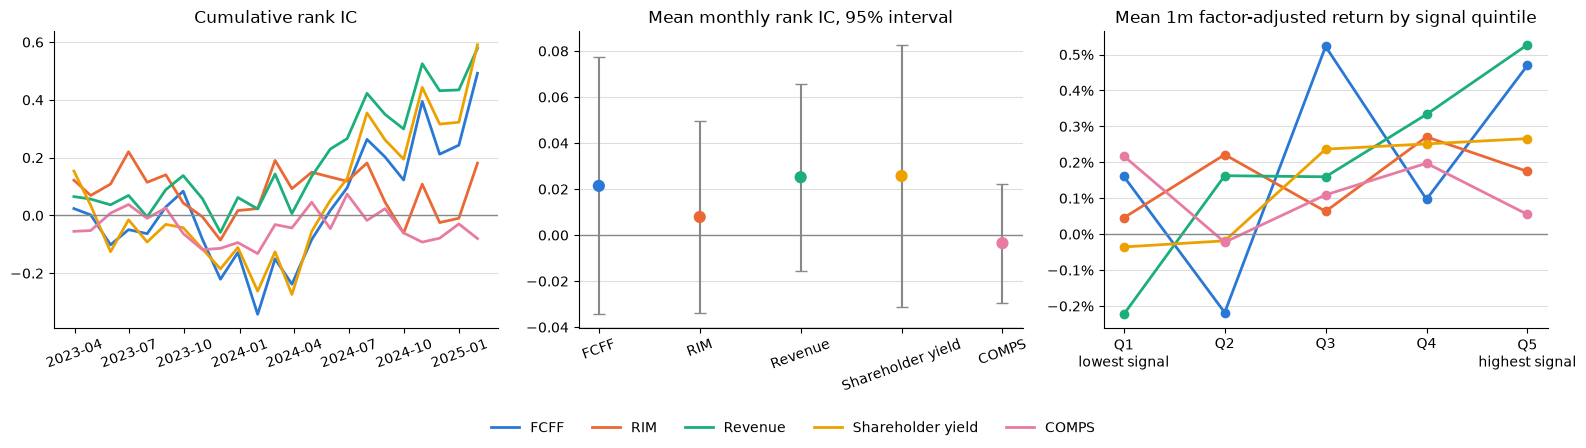

In [14]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

TARGET = 'fwd_adj_1m' # primary target. 1m windows don't overlap, so a plain t-stat is fine
MIN_STOCKS = 30 # a date with fewer stocks holding the signal is skipped
signals = {'FCFF': 'alpha_fcff', 'RIM': 'alpha_rim', 'Revenue': 'alpha_rev', 'Shareholder yield': 'alpha_shy', 'COMPS': 'comps_upside'}
in_dev = (ModelData['split'] == 'development') & (ModelData['rebalance_date'] >= '2023-03-01')

# Shared by every test below
def date_stats(d, col, target):
    """Rank IC, mean target by signal quintile, top-minus-bottom spread and coverage on one rebalance date."""
    s = d[[col, target]].dropna()
    if len(s) < MIN_STOCKS:
        return None
    quintile = pd.qcut(s[col].rank(method='first'), 5, labels=range(1, 6))
    means = s.groupby(quintile, observed=True)[target].mean()
    return {'ic': s[col].corr(s[target], method='spearman'),
            'spread': means[5] - means[1],
            'coverage': len(s) / len(d),
            **{f'q{q}': m for q, m in means.items()}}

def signal_quality(signals, target=TARGET, rows=True):
    """One row per (signal, development date). rows narrows the stocks further, e.g. to a common sample."""
    test = ModelData[in_dev & rows & ModelData[target].notna()]
    return pd.DataFrame([{'model': name, 'rebalance_date': date, **stats}
                         for name, col in signals.items()
                         for date, d in test.groupby('rebalance_date')
                         if (stats := date_stats(d, col, target))])

def t_stat(x, lags=0):
    """Fama-MacBeth: mean of the monthly series over its standard error.
    lags > 0 uses Newey-West standard errors, for overlapping windows (the 3m target on monthly dates)."""
    x = x.dropna()
    if lags == 0:
        return x.mean() / (x.std() / np.sqrt(len(x)))
    e = (x - x.mean()).to_numpy()
    n = len(e)
    var = e @ e / n + 2 * sum((1 - l / (lags + 1)) * (e[l:] @ e[:-l]) / n for l in range(1, lags + 1))
    return x.mean() / np.sqrt(var / n)

def summarise(by_date, lags=0):
    """Test 1's table: one row per signal."""
    g = by_date.groupby('model', sort=False)
    return pd.DataFrame({
        'mean IC': g['ic'].mean(),
        'IC t-stat': g['ic'].apply(t_stat, lags=lags),
        'share of dates IC > 0': g['ic'].apply(lambda x: (x > 0).mean()),
        'Q5 - Q1 per month': g['spread'].mean(),
        'spread t-stat': g['spread'].apply(t_stat, lags=lags),
        'coverage': g['coverage'].mean(),
        'dates': g['ic'].count(),
    })

PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
# the five models and the two composites keep the same colour in every chart
CORE = {**dict(zip(signals, PALETTE)), 'Combined alpha': PALETTE[6], 'Plain-ratio composite': PALETTE[5]}

def colours_for(names):
    """Core models keep their colour; anything else takes the next unused slot, in order."""
    free = iter(c for c in PALETTE if c not in [CORE[n] for n in names if n in CORE])
    return {n: CORE.get(n) or next(free, '#888') for n in names}

def tidy(*axes):
    for ax in axes:
        ax.axhline(0, color='#888', lw=1)
        ax.grid(axis='y', color='#ddd', lw=0.8)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)

def plot_signal_quality(by_date, summary):
    """Cumulative IC (rising steadily = works on most dates), mean IC with a 95% interval,
    and the mean target by signal quintile (rising left to right = the ranking holds across the whole range)."""
    colours = colours_for(summary.index)
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 4.5))
    g = by_date.groupby('model', sort=False)

    for name, d in g:
        ax1.plot(d['rebalance_date'], d['ic'].cumsum(), color=colours[name], lw=2, label=name)
    ax1.set_title('Cumulative rank IC')
    ax1.tick_params(axis='x', rotation=20)

    se = g['ic'].std() / np.sqrt(g['ic'].count())
    ax2.errorbar(summary.index, summary['mean IC'], yerr=1.96 * se, fmt='none', ecolor='#888', capsize=4, lw=1.5, zorder=1)
    ax2.scatter(summary.index, summary['mean IC'], c=[colours[m] for m in summary.index], s=60, zorder=2)
    ax2.set_title('Mean monthly rank IC, 95% interval')
    ax2.tick_params(axis='x', rotation=20)

    quintiles = g[[f'q{q}' for q in range(1, 6)]].mean()
    for name, row in quintiles.iterrows():
        ax3.plot(range(1, 6), row.values, color=colours[name], lw=2, marker='o', ms=6)
    ax3.set_xticks(range(1, 6), ['Q1\nlowest signal', 'Q2', 'Q3', 'Q4', 'Q5\nhighest signal'])
    ax3.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
    ax3.set_title('Mean 1m factor-adjusted return by signal quintile')

    tidy(ax1, ax2, ax3)
    fig.legend(*ax1.get_legend_handles_labels(), loc='lower center', ncol=len(summary), frameon=False)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()

by_date = signal_quality(signals)
summary = summarise(by_date)
display(summary.round(3))
plot_signal_quality(by_date, summary)

**Reading test 1.** Mean IC is the strength of the ranking, the IC t-stat is how sure we can be it isn't zero (roughly 2+ to call it real), and the share of dates IC > 0 is the keep rule's "positive on most dates".

- FCFF, Revenue and Shareholder yield point the right way (mean IC 0.02-0.03), RIM barely, COMPS not at all.
- **No IC t-stat reaches 2**, so on 23 development months none of them is distinguishable from luck yet. Revenue is the closest (spread t-stat ~2, and the only clean Q1 → Q5 staircase).
- The cumulative IC shows most of the gain arrives after mid-2024, so the result leans on one stretch of the sample.

Below: the same test on the secondary targets (3m factor-adjusted, and total returns at both horizons), to check the ranking isn't an artefact of the 1m factor adjustment.

In [15]:
# Same test on the secondary targets. 3m windows overlap on monthly dates, so their t-stats use Newey-West with 2 lags.
targets = {'1m factor-adjusted': ('fwd_adj_1m', 0), '3m factor-adjusted': ('fwd_adj_3m', 2),
           '1m total': ('fwd_return_1m', 0), '3m total': ('fwd_return_3m', 2)}

robust = pd.concat({label: summarise(signal_quality(signals, col), lags)[['mean IC', 'IC t-stat']]
                    for label, (col, lags) in targets.items()}, axis=1)
robust.round(3)

1m factor-adjusted           3m factor-adjusted            \
                             mean IC IC t-stat            mean IC IC t-stat   
model                                                                         
FCFF                           0.021     0.752              0.039     1.155   
RIM                            0.008     0.370              0.018     0.679   
Revenue                        0.025     1.215              0.046     2.458   
Shareholder yield              0.026     0.883              0.049     1.544   
COMPS                         -0.003    -0.264             -0.002    -0.134   

                  1m total           3m total            
                   mean IC IC t-stat  mean IC IC t-stat  
model                                                    
FCFF                 0.007     0.218    0.034     0.647  
RIM                  0.006     0.285    0.026     0.651  
Revenue              0.014     0.621    0.045     1.456  
Shareholder yield    0.023     0.717    0.051     1.077  
COMPS               -0.014    -0.556   -0.007    -0.436

**Result.** The ranking survives the change of target, which is what we want to see:

- At **3 months** the factor-adjusted ICs roughly double for every model except COMPS (valuation gaps close slowly), and Revenue's reaches **t = 2.46** (Newey-West), the only significant number in test 1.
- On **total returns** the 1m ICs shrink to 0.01-0.02. These models lean towards cheap, profitable stocks, and that tilt was a headwind in 2023-25. The factor adjustment strips it out (test 5 shows how big it is).
- COMPS is negative on every target.

### Required-return benchmark (diagnostic)

Expected alpha = implied return − required return, so the benchmark can re-order stocks. This runs the same IC test with three benchmarks, once, and picks one for every test that follows:

- **FF5** (used so far): rf + Σ beta × factor premium
- **CAPM**: rf + market beta × market premium
- **Flat**: rf + market premium for every stock. For the equity-level models this ranks on the implied return alone.

In [16]:
ModelData['ke_capm'] = ModelData['riskfree'] + ModelData['beta_capm'] * ModelData['prem_mkt']
ModelData['ke_flat'] = ModelData['riskfree'] + ModelData['prem_mkt']
alpha_signals = {m: c for m, c in signals.items() if c.startswith('alpha_')}
benchmarks = {'FF5': 'ke', 'CAPM': 'ke_capm', 'Flat': 'ke_flat'}

bench = {}
for name, ke in benchmarks.items():
    cols = alphas(ModelData[ke]).add_suffix('_' + name)
    ModelData[cols.columns] = cols
    bench[name] = summarise(signal_quality({m: c + '_' + name for m, c in alpha_signals.items()}))[['mean IC', 'IC t-stat']]
bench = pd.concat(bench, axis=1)
bench.loc['Average'] = bench.mean()
display(bench.round(3))

BENCHMARK = 'CAPM' # chosen once from the table above, see the note below
ModelData['req_equity'] = ModelData[benchmarks[BENCHMARK]]
ModelData['req_firm'] = wacc(ModelData['req_equity'])
chosen = alphas(ModelData['req_equity'])
ModelData[chosen.columns] = chosen

FF5              CAPM              Flat          
                  mean IC IC t-stat mean IC IC t-stat mean IC IC t-stat
model                                                                  
FCFF                0.021     0.752   0.035     1.057   0.024     1.051
RIM                 0.008     0.370   0.025     0.886  -0.001    -0.066
Revenue             0.025     1.215   0.036     1.237   0.029     1.403
Shareholder yield   0.026     0.883   0.041     1.289   0.025     1.397
Average             0.020     0.805   0.034     1.117   0.019     0.946

**Result.** CAPM gives the highest IC for **every** model (average 0.034, against 0.020 for FF5 and 0.019 flat), so it's used from here on (`BENCHMARK = 'CAPM'`). This is a development-period choice, made once; log it in the variant log.

- The likely reason: 252-day betas on HML, RMW and CMA are noisy, so FF5 mostly adds noise to the required return.
- The flat rate kills RIM (IC −0.001): RIM's implied return only ranks well once it's compared with a stock-specific required return.
- Caveat: CAPM doesn't charge the models for their value and profitability tilt, so that tilt stays in the alpha. Test 5 shows the cost.

### Test 2: Beat the simpler version

Each model against the plain ratio it's built from. If a model can't beat its own ratio, its growth and fade assumptions add nothing. Each pair is scored on the **same stocks** (rows where both exist), so coverage can't decide it, and the difference in monthly ICs gets its own t-stat.

| Model | Plain ratio |
|---|---|
| FCFF | FCF yield (FCFF / EV) |
| RIM | Book-to-price and earnings yield |
| Revenue | Sales-to-EV |
| Shareholder yield | Payout / market cap |
| COMPS | Sector-relative EV/EBITDA (sector median ÷ firm − 1) |

FCFF is also compared with the **dashboard's current forward-DCF margin** (`valuation.fcff_verdict`, run on the same statements with the dashboard's growth rule), which answers "does reverse DCF beat the current approach?".

,model,compared with,model IC,ratio IC,difference,difference t-stat,model wins on share of dates,beats it
0,FCFF,FCF yield,0.035,0.015,0.020,0.924,0.565,True
1,FCFF,Forward DCF margin (dashboard),0.047,0.025,0.021,0.961,0.609,True
2,RIM,Book-to-price,0.025,0.005,0.019,0.936,0.522,True
3,RIM,Earnings yield,0.025,-0.002,0.026,1.421,0.652,True
4,Revenue,Sales-to-EV,0.036,0.021,0.014,0.567,0.478,True
5,Shareholder yield,Payout / market cap,0.041,0.024,0.017,0.748,0.478,True
6,COMPS,Sector-relative EV/EBITDA,-0.003,0.001,-0.004,-1.222,0.348,False


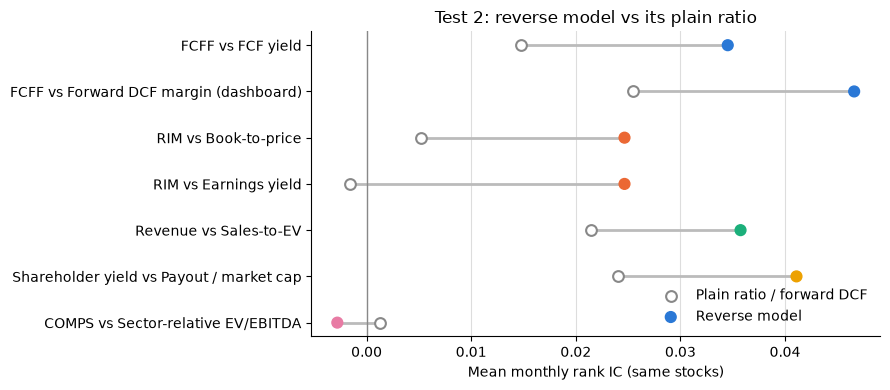

In [17]:
import valuation

pos = lambda s: s.where(s > 0)
ModelData['fcf_yield'] = ModelData['fcff'] / pos(ModelData['ev'])
ModelData['book_to_price'] = ModelData['bookequity'] / pos(ModelData['equity'])
ModelData['earnings_yield'] = ModelData['netincome'] / pos(ModelData['equity'])
ModelData['sales_to_ev'] = ModelData['revenue'] / pos(ModelData['ev'])
ModelData['shy_ratio'] = ModelData['shareholder_payout'] / pos(ModelData['equity'])
ModelData['ev_ebitda_rel'] = sector_median(ev_ebitda) / ev_ebitda - 1 # ev_ebitda from the COMPS cell

def forward_dcf_margin(close, ebit, dna, capex, dnwc, tax, totaldebt, netdebt, interest, shares, rf, ke, g0_raw, sector):
    """The dashboard's FCFF margin of safety, with its growth rule: half of trailing growth, capped to [0, 12%], 4% if unknown."""
    growth = 0.04 if np.isnan(g0_raw) else min(max(0.5 * g0_raw, 0), 0.12)
    ke = min(max(ke, valuation.MIN_COST_OF_EQUITY), valuation.MAX_COST_OF_EQUITY) # the dashboard clamps Ke
    v = valuation.fcff_verdict(close, ebit, dna, capex, dnwc, tax, totaldebt, netdebt, interest, shares, rf, ke, growth, 4, sector)
    return np.nan if v is None else v['margin_of_safety']

ModelData['fwd_dcf_margin'] = apply_rows(forward_dcf_margin, ['close', 'ebit', 'dna', 'capex', 'dnwc', 'tax', 'totaldebt', 'netdebt',
                                                              'interestexpense', 'shares', 'riskfree', 'ke', 'g0_raw', 'sector'])

pairs = [('FCFF', 'FCF yield', 'fcf_yield'),
         ('FCFF', 'Forward DCF margin (dashboard)', 'fwd_dcf_margin'),
         ('RIM', 'Book-to-price', 'book_to_price'),
         ('RIM', 'Earnings yield', 'earnings_yield'),
         ('Revenue', 'Sales-to-EV', 'sales_to_ev'),
         ('Shareholder yield', 'Payout / market cap', 'shy_ratio'),
         ('COMPS', 'Sector-relative EV/EBITDA', 'ev_ebitda_rel')]

rows = []
for model, ratio, col in pairs:
    both = ModelData[signals[model]].notna() & ModelData[col].notna()
    ic = signal_quality({model: signals[model], ratio: col}, rows=both).pivot(index='rebalance_date', columns='model', values='ic')
    diff = ic[model] - ic[ratio]
    rows.append({'model': model, 'compared with': ratio, 'model IC': ic[model].mean(), 'ratio IC': ic[ratio].mean(),
                 'difference': diff.mean(), 'difference t-stat': t_stat(diff), 'model wins on share of dates': (diff > 0).mean()})
test2 = pd.DataFrame(rows)
test2['beats it'] = test2['difference'] >= 0
display(test2.round(3))

# Dot plot: each model's IC (filled, its colour) against the comparison on the same stocks (hollow grey)
fig, ax = plt.subplots(figsize=(9, 4))
y = np.arange(len(test2))[::-1]
ax.hlines(y, test2['ratio IC'], test2['model IC'], color='#bbb', lw=2)
ax.scatter(test2['ratio IC'], y, s=60, facecolors='white', edgecolors='#888', lw=1.5, zorder=3, label='Plain ratio / forward DCF')
ax.scatter(test2['model IC'], y, s=60, c=[CORE[m] for m in test2['model']], zorder=3, label='Reverse model')
ax.set_yticks(y, test2['model'] + ' vs ' + test2['compared with'])
ax.axvline(0, color='#888', lw=1)
ax.grid(axis='x', color='#ddd', lw=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('Mean monthly rank IC (same stocks)')
ax.set_title('Test 2: reverse model vs its plain ratio')
ax.legend(frameon=False, loc='lower right')
fig.tight_layout()
plt.show()

**Result.** On the same stocks, every reverse model beats its plain ratio except COMPS, by +0.014 to +0.026 IC. Reverse FCFF also beats the dashboard's forward-DCF margin (0.047 against 0.025 where both exist).

- None of the differences is significant (t ≤ 1.4), and each model only wins on about half the dates. So the rule's "at least matches" holds, but "clearly better" isn't shown yet.
- The plain ratios themselves are weak in this window: earnings yield and book-to-price are close to zero.

### Growth specifications

From section 6: with flat growth the implied return is roughly yield + g_L, i.e. the plain ratio again, so the model only adds information through its growth assumptions. Three specifications, each fading linearly to g_L over N years:

1. **Flat**: g0 = g_L
2. **Trailing** (used so far): the firm's own revenue CAGR
3. **Sector**: the sector median of trailing g0 at the rebalance date

Then N = 3 and N = 10 on the trailing spec as a robustness check (RIM included, since its ROE fade also uses N). These are solved on the development dates only.

mean IC                               IC t-stat           \
spec                 flat trailing sector  N = 3 N = 10      flat trailing   
model                                                                        
FCFF                0.032    0.035  0.031  0.033  0.037     0.978    1.057   
RIM                   NaN    0.025    NaN  0.023  0.029       NaN    0.886   
Revenue             0.032    0.036  0.033  0.034  0.040     1.109    1.237   
Shareholder yield   0.040    0.041  0.039  0.040  0.042     1.257    1.289   

                                        
spec              sector  N = 3 N = 10  
model                                   
FCFF               0.959  1.016  1.160  
RIM                  NaN  0.778  1.141  
Revenue            1.124  1.174  1.370  
Shareholder yield  1.263  1.273  1.318

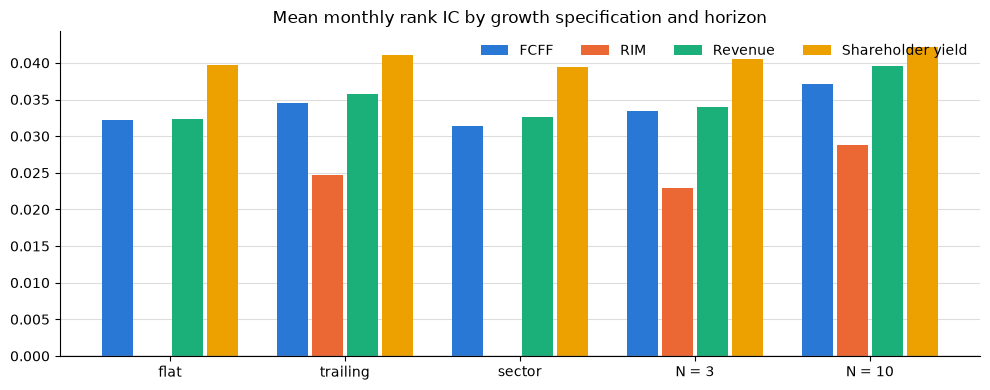

In [18]:
ModelData['g0_sector'] = sector_median(ModelData['g0']).fillna(ModelData['g_L'])

# (solver, its columns with 'G' where g0 goes, required return it's compared with)
growth_models = {'FCFF': (implied_r, ['fcff', 'G', 'g_L', 'ev'], 'req_firm'),
                 'Revenue': (implied_r_rev, ['revenue', 'G', 'g_L', 'margin', 'margin_sector', 'ev'], 'req_firm'),
                 'Shareholder yield': (implied_r, ['shareholder_payout', 'G', 'g_L', 'equity'], 'req_equity'),
                 'RIM': (implied_r_rim, ['bookequity', 'roe', 'roe_sector', 'payout', 'g_L', 'equity'], 'req_equity')}

def variant_alpha(model, g0_col='g0_used'):
    """Expected alpha for one model under the current N and a given g0 column, development rows only."""
    fn, cols, req = growth_models[model]
    r = pd.Series(np.nan, index=ModelData.index)
    r[in_dev] = apply_rows(fn, [g0_col if c == 'G' else c for c in cols], rows=in_dev)
    return r - ModelData[req]

variants = {}
for model in ['FCFF', 'Revenue', 'Shareholder yield']:
    for spec, g0_col in {'flat': 'g_L', 'sector': 'g0_sector'}.items():
        variants[(model, spec)] = variant_alpha(model, g0_col)
    variants[(model, 'trailing')] = ModelData[signals[model]]
variants[('RIM', 'trailing')] = ModelData[signals['RIM']]

for n in (3, 10):
    N = n # the shared fade() reads N when it's called
    for model in growth_models:
        variants[(model, f'N = {n}')] = variant_alpha(model)
N = 5

for (model, spec), alpha in variants.items():
    ModelData[f'v_{model}_{spec}'] = alpha
growth_ic = summarise(signal_quality({f'{m}|{s}': f'v_{m}_{s}' for m, s in variants}))
growth_ic.index = pd.MultiIndex.from_tuples([tuple(i.split('|')) for i in growth_ic.index], names=['model', 'spec'])
spec_order = ['flat', 'trailing', 'sector', 'N = 3', 'N = 10']
growth_table = growth_ic['mean IC'].unstack()[spec_order]
display(pd.concat({'mean IC': growth_table, 'IC t-stat': growth_ic['IC t-stat'].unstack()[spec_order]}, axis=1).round(3))

fig, ax = plt.subplots(figsize=(10, 4))
width = 0.8 / len(growth_table)
for i, (model, row) in enumerate(growth_table.iterrows()):
    ax.bar(np.arange(len(spec_order)) + i * width, row.values, width * 0.9, color=CORE[model], label=model)
ax.set_xticks(np.arange(len(spec_order)) + width * (len(growth_table) - 1) / 2, spec_order)
ax.set_title('Mean monthly rank IC by growth specification and horizon')
tidy(ax)
ax.legend(frameon=False, ncol=4)
fig.tight_layout()
plt.show()

**Result.** The growth assumption adds very little.

- **Trailing beats flat** for every model, but only by 0.001-0.004 IC. **Sector-median growth is no better than flat.** Most of each model's signal is the yield it starts from, not the growth path.
- **N = 10** is slightly better than N = 5 for every model and N = 3 slightly worse. The models' order doesn't change, so N = 5 stays: picking N = 10 on differences this small would be fitting noise.

### Keep rule

A model joins the consensus only if **both** hold on the development dates: its IC is positive on most dates, and it at least matches its plain ratio(s) from test 2 (the forward-DCF comparison isn't part of the rule).

In [19]:
final = summarise(signal_quality(signals)) # on the chosen benchmark
ratio_pairs = test2[test2['compared with'] != 'Forward DCF margin (dashboard)']
keep = pd.DataFrame({'mean IC': final['mean IC'],
                     'share of dates IC > 0': final['share of dates IC > 0'],
                     'IC > 0 on most dates': final['share of dates IC > 0'] > 0.5,
                     'matches its plain ratio': ratio_pairs.groupby('model')['beats it'].all()})
keep['kept'] = keep['IC > 0 on most dates'] & keep['matches its plain ratio']
kept = keep.index[keep['kept']].tolist()
keep.round(3)

,mean IC,share of dates IC > 0,IC > 0 on most dates,matches its plain ratio,kept
model,,,,,
COMPS,-0.003,0.522,True,False,False
FCFF,0.035,0.652,True,True,True
RIM,0.025,0.609,True,True,True
Revenue,0.036,0.696,True,True,True
Shareholder yield,0.041,0.609,True,True,True


**Result.** FCFF, RIM, Revenue and Shareholder yield are **kept**. COMPS is **dropped**: its mean IC is negative and it loses to its own ratio (it only scrapes the "most dates" rule, at 52%). The kept models pass the "most dates" rule only modestly, at 61-70% of months.

### Test 3: Combination

The equal-weight average of the kept models' expected alphas (whichever are available for a stock), against the best single kept model and a **plain-ratio composite**: the average within-date percentile rank of the six plain ratios. The question is whether the combined signal beats its parts and beats simple value.

,mean IC,IC t-stat,share of dates IC > 0,Q5 - Q1 per month,spread t-stat,coverage,dates
model,,,,,,,
Combined alpha,0.036,1.168,0.609,0.004,0.563,0.979,23
Shareholder yield,0.041,1.289,0.609,0.006,1.001,0.896,23
Plain-ratio composite,0.012,0.678,0.652,-0.002,-0.467,0.982,23


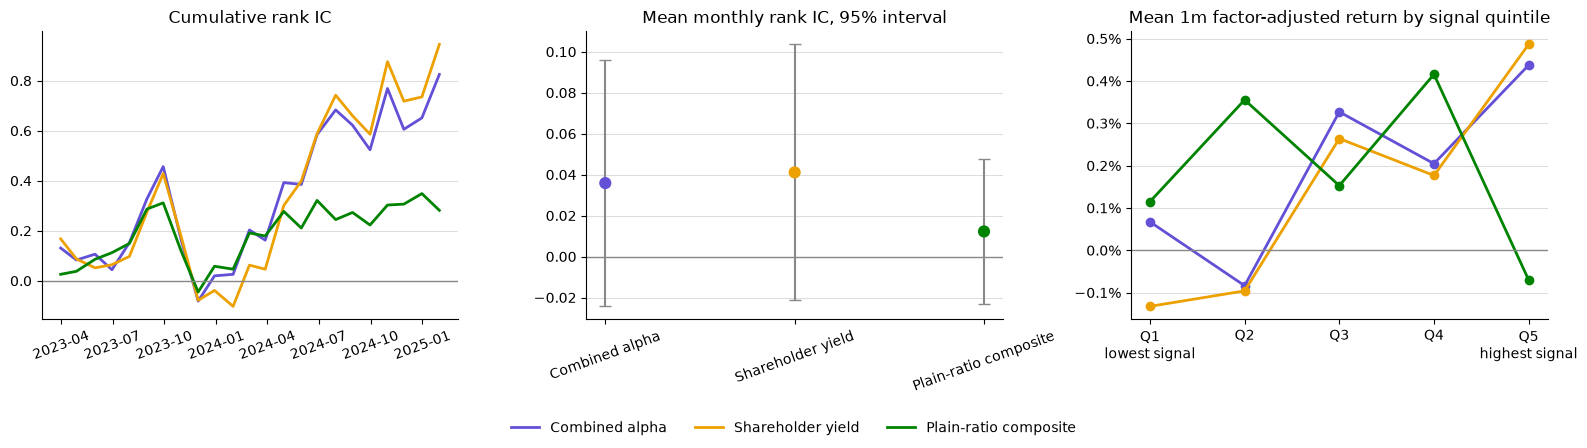

In [20]:
combine = [signals[m] for m in kept if signals[m].startswith('alpha_')] # COMPS is an upside, not an alpha, so it can't be averaged in
ModelData['alpha_combined'] = ModelData[combine].mean(axis=1)

ratio_cols = ['fcf_yield', 'book_to_price', 'earnings_yield', 'sales_to_ev', 'shy_ratio', 'ev_ebitda_rel']
ModelData['ratio_composite'] = ModelData.groupby('rebalance_date')[ratio_cols].rank(pct=True).mean(axis=1)

best = final.loc[kept, 'mean IC'].idxmax()
combo_signals = {'Combined alpha': 'alpha_combined', best: signals[best], 'Plain-ratio composite': 'ratio_composite'}
combo_by_date = signal_quality(combo_signals)
combo = summarise(combo_by_date)
display(combo.round(3))
plot_signal_quality(combo_by_date, combo)

**Result. Half a pass.**

- The combined alpha (IC 0.036, 98% coverage) clearly beats the **plain-ratio composite** (0.012, whose top fifth actually did worst). The reverse models beat simple value.
- It does **not** beat the best single model, Shareholder yield (0.041, 90% coverage). The four models overlap (rank correlations 0.4-0.6), so averaging them buys coverage rather than accuracy.

### Test 4: Calibration

Test 1 only checks the *ordering*. Before expected alpha can feed the optimiser as a return forecast, its *size* has to mean something. Within each date, stocks are sorted into deciles of predicted alpha; each decile's average predicted alpha (per year) is plotted against its average realised factor-adjusted return (1m × 12). A calibrated signal sits on the 45° line.

The **Fama-MacBeth slope** (realised on predicted, per date, then averaged) is the scale factor: 1 = calibrated, 0 = no information in the size, between 0 and 1 = shrink alpha by that factor before using it. Alpha is clipped to its 1st-99th percentile within each date for the slope, so a few unsolvable-looking implied returns near R_MAX can't drive it.

,slope,slope t-stat,"predicted alpha, top - bottom decile","realised, top - bottom decile"
Combined alpha,0.137,0.244,0.186,-0.015
FCFF,0.347,0.631,0.197,0.079
RIM,-0.143,-0.309,0.194,-0.094
Revenue,0.146,0.418,0.270,0.078
Shareholder yield,0.574,1.016,0.167,0.077


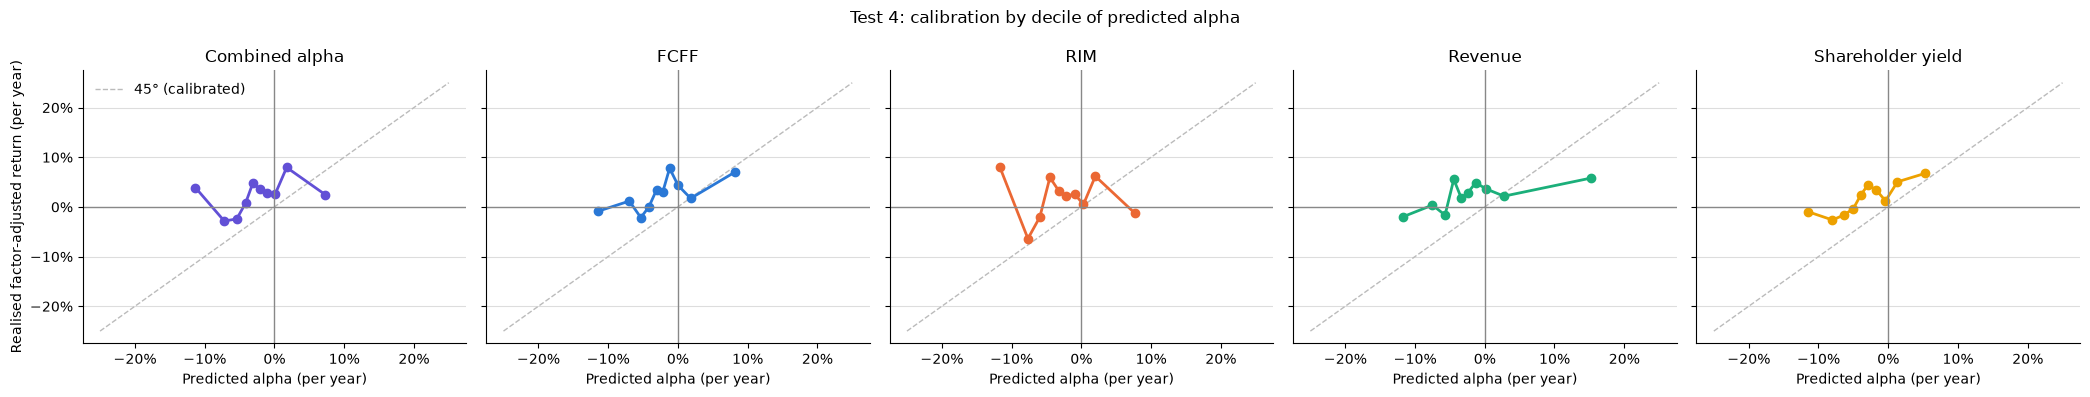

In [21]:
def calibration(col):
    """Decile means of predicted vs realised (annualised), and the per-date slope of realised on predicted."""
    d = ModelData.loc[in_dev & ModelData[TARGET].notna() & ModelData[col].notna(), ['rebalance_date', col, TARGET]].copy()
    d['realised'] = 12 * d[TARGET]
    by = d.groupby('rebalance_date')[col]
    d['predicted'] = d[col].clip(by.transform(lambda x: x.quantile(0.01)), by.transform(lambda x: x.quantile(0.99)))
    d['decile'] = by.transform(lambda x: pd.qcut(x.rank(method='first'), 10, labels=False)) + 1
    slopes = d.groupby('rebalance_date').apply(lambda x: np.polyfit(x['predicted'], x['realised'], 1)[0])
    return d.groupby('decile')[['predicted', 'realised']].mean(), slopes

calib_signals = {'Combined alpha': 'alpha_combined', **{m: signals[m] for m in kept if signals[m].startswith('alpha_')}}
results = {name: calibration(col) for name, col in calib_signals.items()}
calib = pd.DataFrame({name: {'slope': s.mean(), 'slope t-stat': t_stat(s),
                             'predicted alpha, top - bottom decile': dec['predicted'].iloc[-1] - dec['predicted'].iloc[0],
                             'realised, top - bottom decile': dec['realised'].iloc[-1] - dec['realised'].iloc[0]}
                      for name, (dec, s) in results.items()}).T
display(calib.round(3))

colours = colours_for(list(calib_signals))
fig, axes = plt.subplots(1, len(results), figsize=(4.2 * len(results), 4), sharex=True, sharey=True, squeeze=False)
for ax, (name, (dec, _)) in zip(axes[0], results.items()):
    lim = [-0.25, 0.25]
    ax.plot(lim, lim, color='#bbb', lw=1, ls='--', label='45° (calibrated)')
    ax.plot(dec['predicted'], dec['realised'], color=colours[name], lw=2, marker='o', ms=6)
    ax.axvline(0, color='#888', lw=1)
    ax.set_title(name)
    ax.set_xlabel('Predicted alpha (per year)')
    ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    tidy(ax)
axes[0][0].set_ylabel('Realised factor-adjusted return (per year)')
axes[0][0].legend(frameon=False, loc='upper left')
fig.suptitle('Test 4: calibration by decile of predicted alpha')
fig.tight_layout()
plt.show()

**Result. Not calibrated.** Every slope is well below 1 and none is significant.

- The combined alpha's slope is **0.14 (t = 0.24)**: a 10-point gap in predicted alpha has gone with about 1.4 points of realised return. Its top decile was predicted to beat the bottom by 18.6% a year and actually trailed it by 1.5%.
- RIM's slope is negative. Shareholder yield's is the best at 0.57, but its t-stat is only 1.0.
- For the portfolio stage, raw expected alpha can't go into the optimiser as a return forecast. It would need heavy shrinking (by the slope), or replacing with ranks.

### Test 5: Factor attribution

Each month, go long the top fifth and short the bottom fifth of each signal (equal weight, raw 1m returns), then regress that long-short return on the five Fama-French factors' returns over the same month. The intercept is the return left over after value, size, profitability and investment exposure (annualised × 12). Large factor loadings mean the signal is mostly a factor bet you could buy more cheaply.

,mean L/S per month,alpha per year,alpha t-stat,beta mkt,beta smb,beta hml,beta rmw,beta cma,R^2
FCFF,-0.010,-0.093,-1.224,-0.373,-0.194,0.999,0.840,0.172,0.843
RIM,-0.011,-0.096,-1.681,-0.311,-0.111,0.976,0.972,0.373,0.914
Revenue,-0.009,-0.069,-1.037,-0.302,-0.079,0.795,1.051,0.481,0.880
Shareholder yield,-0.004,-0.019,-0.274,-0.315,-0.370,0.792,0.586,0.436,0.843
COMPS,-0.005,-0.052,-1.057,-0.020,0.311,0.653,0.441,-0.092,0.818
Combined alpha,-0.008,-0.053,-0.860,-0.349,-0.188,0.844,1.002,0.527,0.906
Plain-ratio composite,-0.006,-0.052,-1.194,-0.205,0.182,0.960,0.764,0.068,0.925


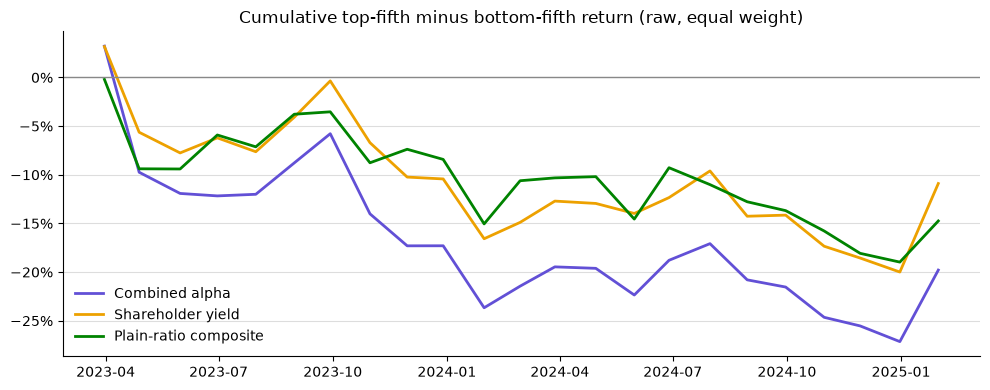

In [22]:
fwd_factors = [f'fwd_{f}_1m' for f in FACTORS]
monthly_factors = ModelData[in_dev].groupby('rebalance_date')[fwd_factors].first()

def long_short(col):
    """Monthly return of top fifth minus bottom fifth by signal, equal weight, raw 1m returns."""
    d = ModelData.loc[in_dev & ModelData['fwd_return_1m'].notna() & ModelData[col].notna(), ['rebalance_date', col, 'fwd_return_1m']]
    d = d[d.groupby('rebalance_date')[col].transform('count') >= MIN_STOCKS] # same date rule as test 1
    q = d.groupby('rebalance_date')[col].transform(lambda x: pd.qcut(x.rank(method='first'), 5, labels=False))
    leg = lambda k: d[q == k].groupby('rebalance_date')['fwd_return_1m'].mean()
    return leg(4) - leg(0)

def ols(y, X):
    """OLS with an intercept: coefficients, t-stats and R^2."""
    A = np.column_stack([np.ones(len(X)), X])
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    resid = y - A @ coef
    se = np.sqrt(np.diag(np.linalg.inv(A.T @ A)) * (resid @ resid) / (len(y) - A.shape[1]))
    return coef, coef / se, 1 - resid.var() / y.var()

def attribution(signals):
    """One row per signal: mean long-short return, FF5 alpha (annualised) with its t-stat, the five loadings and R^2."""
    rows, paths = {}, {}
    for name, col in signals.items():
        ls = long_short(col)
        coef, t, r2 = ols(ls.to_numpy(), monthly_factors.loc[ls.index].to_numpy())
        rows[name] = {'mean L/S per month': ls.mean(), 'alpha per year': 12 * coef[0], 'alpha t-stat': t[0],
                      **{f'beta {f}': b for f, b in zip(FACTORS, coef[1:])}, 'R^2': r2}
        paths[name] = (1 + ls).cumprod() - 1
    return pd.DataFrame(rows).T, pd.DataFrame(paths)

attr_signals = {**signals, 'Combined alpha': 'alpha_combined', 'Plain-ratio composite': 'ratio_composite'}
attr, paths = attribution(attr_signals)
display(attr.round(3))

show = ['Combined alpha', best, 'Plain-ratio composite']
colours = colours_for(show)
fig, ax = plt.subplots(figsize=(10, 4))
for name in show:
    ax.plot(paths.index, paths[name], color=colours[name], lw=2, label=name)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_title('Cumulative top-fifth minus bottom-fifth return (raw, equal weight)')
tidy(ax)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

**Result. Fails.** On raw returns the long-short portfolios **lost money**.

- **Loss:** the combined alpha's top-minus-bottom fifth averaged **−0.8% a month**, about −20% cumulative over the development window.
- **Why:** the regression has R² ≈ 0.9, with large HML (+0.84) and RMW (+1.0) loadings and a negative market beta. The models mostly buy cheap, profitable, lower-beta stocks and sell expensive ones. That's a value/quality factor bet, and it did badly in 2023-25's market led by mega-cap growth.
- **After the factors:** the alpha is **−5.3% a year (t = −0.86)**. There's no evidence of return beyond value, size, profitability and investment exposure.
- **Tension with test 1:** test 1 removes each *stock's* estimated factor exposure and finds a positive IC. This test removes the *portfolio's* exposure and finds a negative alpha. When two reasonable adjustments disagree in sign, the result is fragile.

## Other signals (no new data needed)

The reverse models are all versions of one idea: value. The literature's most reliable cross-sectional signals that can be built from tables already loaded:

| Signal | Built from | Why |
|---|---|---|
| **Sector-neutral value** | Combined alpha minus its sector median at each date | Raw value ranks are partly a sector bet (cheap sectors stay cheap). Ranking within sector usually raises value's IC |
| **Momentum 12-1** | `daily_prices`: return from 12 months to 1 month ago | The strongest documented anomaly (Jegadeesh & Titman 1993), and not one of the FF5 factors, so it isn't removed by the factor adjustment |
| **1-month reversal** | `daily_prices`: minus last month's return | Short-term overreaction (Jegadeesh 1990) |
| **Low volatility** | `daily_prices`: minus the std of daily returns over a year | Low-risk anomaly (Ang et al. 2006, Frazzini & Pedersen 2014) |
| **Quality (ROIC)** | EBIT(1 − tax) / invested capital | Profitable firms earn more than their price implies (Novy-Marx 2013) |
| **Magic formula** | Average percentile rank of EBIT/EV and ROIC | Greenblatt's value + quality blend |
| **Earnings surprise** | `earnings_dates`: (reported − estimated EPS) / price, latest report before the date | Post-earnings drift (Bernard & Thomas 1989) |
| **Gross profitability** | `statement_items`: gross profit / total assets | Novy-Marx (2013): the cleanest profitability measure |
| **Low accruals** | `statement_items`: −(net income − operating cash flow) / total assets | Earnings backed by cash persist; accrual-heavy earnings don't (Sloan 1996) |
| **Low asset growth** | `statement_items`: minus the 1-year growth in total assets | Fast asset growers underperform (Cooper, Gulen & Schill 2008) |
| **Value + momentum** | Average percentile rank of combined alpha and momentum | Value and momentum are negatively correlated, so the blend is steadier than either (Asness, Moskowitz & Pedersen 2013) |

All are point-in-time: prices up to the rebalance date, the same 60-day-lagged statement each row already uses, and earnings reports dated strictly before the rebalance date.

,mean IC,IC t-stat,share of dates IC > 0,Q5 - Q1 per month,spread t-stat,coverage,dates
model,,,,,,,
Value + momentum,0.056,1.907,0.696,0.008,1.384,0.977,23
Combined alpha (value),0.036,1.168,0.609,0.004,0.563,0.979,23
Momentum 12-1,0.029,1.171,0.652,0.005,0.900,0.998,23
Sector-neutral value,0.027,1.096,0.522,0.004,0.658,0.979,23
Earnings surprise,0.025,1.489,0.652,0.003,0.715,0.989,23
Low volatility,0.011,0.342,0.348,-0.003,-0.386,1.000,23
Low asset growth,0.004,0.229,0.538,0.001,0.238,0.860,13
Gross profitability,-0.002,-0.088,0.609,-0.003,-0.580,0.894,23
Low accruals,-0.002,-0.134,0.478,0.001,0.327,0.999,23


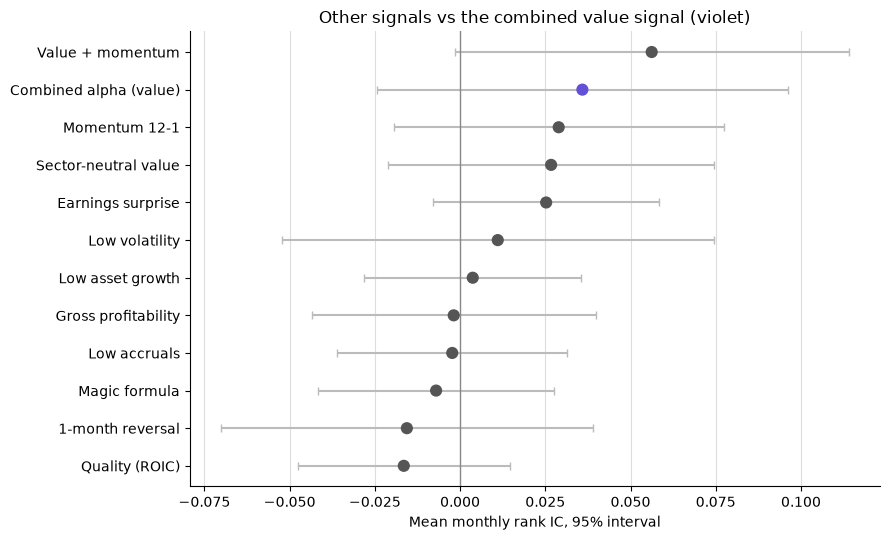

,mean L/S per month,alpha per year,alpha t-stat,beta mkt,beta smb,beta hml,beta rmw,beta cma,R^2
Combined alpha (value),-0.008,-0.053,-0.860,-0.349,-0.188,0.844,1.002,0.527,0.906
Sector-neutral value,-0.006,-0.051,-0.811,-0.317,-0.213,0.780,0.736,0.234,0.852
Momentum 12-1,0.010,-0.006,-0.048,0.501,-0.539,-0.252,-0.413,-0.058,0.422
1-month reversal,-0.006,-0.183,-1.326,0.079,-0.509,0.357,-0.194,-0.629,0.154
Low volatility,-0.016,-0.096,-0.748,-0.623,-0.380,0.408,0.715,0.632,0.700
Quality (ROIC),-0.006,-0.130,-1.986,0.043,-0.259,0.180,0.633,-0.089,0.521
Magic formula,-0.007,-0.121,-2.374,-0.033,-0.082,0.560,0.640,-0.077,0.731
Earnings surprise,0.004,-0.052,-0.899,0.402,-0.229,0.078,0.393,0.022,0.431
Gross profitability,0.001,-0.061,-0.860,0.180,-0.301,-0.250,-0.181,-0.262,0.516
Low accruals,0.003,0.042,0.633,-0.083,-0.194,-0.339,-0.381,-0.031,0.490


In [23]:
adj = prices.pivot(index='date', columns='ticker', values='adj_close')
dates = ModelData['rebalance_date'].drop_duplicates()
key = pd.MultiIndex.from_frame(ModelData[['rebalance_date', 'ticker']])

def price_signal(fn):
    """fn(position of the last trading day <= rebalance date) -> Series by ticker, for every date, aligned to ModelData rows."""
    out = {d: fn(adj.index.searchsorted(d, side='right') - 1) for d in dates}
    return pd.concat(out, names=['rebalance_date', 'ticker']).reindex(key).to_numpy()

ModelData['momentum'] = price_signal(lambda p: adj.iloc[p - 21] / adj.iloc[p - 252] - 1)
ModelData['reversal'] = price_signal(lambda p: -(adj.iloc[p] / adj.iloc[p - 21] - 1))
ModelData['low_vol'] = price_signal(lambda p: -daily.iloc[p - 251:p + 1].std().where(daily.iloc[p - 251:p + 1].count() >= MIN_BETA_OBS))

ModelData['value_sector_neutral'] = ModelData['alpha_combined'] - sector_median(ModelData['alpha_combined'])
ModelData['roic'] = ModelData['ebit'] * (1 - ModelData['tax']) / pos(ModelData['investedcapital'])
ModelData['ebit_ev'] = ModelData['ebit'] / pos(ModelData['ev'])
pct_rank = lambda cols: ModelData.groupby('rebalance_date')[cols].rank(pct=True).mean(axis=1, skipna=False)
ModelData['magic_formula'] = pct_rank(['ebit_ev', 'roic'])
ModelData['value_momentum'] = pct_rank(['alpha_combined', 'momentum'])

# Earnings surprise from the latest report strictly before the rebalance date, if it's within ~a quarter
with connect() as conn:
    earnings = query_df(conn, "select ticker, report_date, eps_estimate, reported_eps from backtest.earnings_dates where eps_estimate is not null and reported_eps is not null")
earnings['report_date'] = pd.to_datetime(earnings['report_date']).dt.tz_localize(None)
latest = pd.merge_asof(ModelData[['rebalance_date', 'ticker', 'close']].sort_values('rebalance_date'),
                       earnings.sort_values('report_date'), left_on='rebalance_date', right_on='report_date',
                       by='ticker', allow_exact_matches=False, tolerance=pd.Timedelta(days=100))
latest['surprise'] = (latest['reported_eps'] - latest['eps_estimate']) / latest['close']
ModelData['surprise'] = latest.set_index(['rebalance_date', 'ticker'])['surprise'].reindex(key).to_numpy()
ModelData['momentum_surprise'] = pct_rank(['momentum', 'surprise']) # momentum + earnings surprise (SUE vs the analyst forecast)

# Gross profit, total assets and operating cash flow aren't in backtest.models, but they're in statement_items for the same
# statement each row already uses (same period_end, so the same 60-day lag)
with connect() as conn:
    items = query_df(conn, """select ticker, period_end, item, value from backtest.statement_items
                              where frequency = 'annual' and item in ('Gross Profit', 'Total Assets', 'Operating Cash Flow')""")
items['period_end'] = pd.to_datetime(items['period_end'])
items = items.pivot_table(index=['ticker', 'period_end'], columns='item', values='value').sort_index()
items['asset_growth'] = items['Total Assets'] / items.groupby('ticker')['Total Assets'].shift() - 1
items = items.reindex(pd.MultiIndex.from_frame(ModelData[['ticker', 'period_end']]))
assets = pos(pd.Series(items['Total Assets'].to_numpy(), index=ModelData.index))
ModelData['gross_profitability'] = items['Gross Profit'].to_numpy() / assets
ModelData['low_accruals'] = -(ModelData['netincome'] - items['Operating Cash Flow'].to_numpy()) / assets
ModelData['low_asset_growth'] = -items['asset_growth'].to_numpy()

other_signals = {'Combined alpha (value)': 'alpha_combined', 'Sector-neutral value': 'value_sector_neutral', 'Momentum 12-1': 'momentum',
                 '1-month reversal': 'reversal', 'Low volatility': 'low_vol', 'Quality (ROIC)': 'roic', 'Magic formula': 'magic_formula',
                 'Earnings surprise': 'surprise', 'Gross profitability': 'gross_profitability', 'Low accruals': 'low_accruals',
                 'Low asset growth': 'low_asset_growth', 'Value + momentum': 'value_momentum',
                 'Momentum + surprise': 'momentum_surprise'}
other_by_date = signal_quality(other_signals)
other = summarise(other_by_date).sort_values('mean IC', ascending=False)
display(other.round(3))

# One dot per signal, so no colour legend needed: mean IC with a 95% interval, value baseline highlighted
se = other_by_date.groupby('model')['ic'].agg(lambda x: x.std() / np.sqrt(x.count())).reindex(other.index)
fig, ax = plt.subplots(figsize=(9, 5.5))
y = np.arange(len(other))[::-1]
ax.errorbar(other['mean IC'], y, xerr=1.96 * se, fmt='none', ecolor='#bbb', capsize=3, lw=1.5)
ax.scatter(other['mean IC'], y, s=60, zorder=3, c=[CORE['Combined alpha'] if n == 'Combined alpha (value)' else '#555' for n in other.index])
ax.set_yticks(y, other.index)
ax.axvline(0, color='#888', lw=1)
ax.grid(axis='x', color='#ddd', lw=0.8)
ax.set_axisbelow(True)
ax.spines[['top', 'right']].set_visible(False)
ax.set_xlabel('Mean monthly rank IC, 95% interval')
ax.set_title('Other signals vs the combined value signal (violet)')
fig.tight_layout()
plt.show()

other_attr, _ = attribution(other_signals)
display(other_attr.round(3))

**Result.**

- **Value + momentum is the strongest signal in the notebook**: IC 0.056 (t = 1.9), positive in 70% of months. The blend works here because momentum did well in exactly the period value did badly. Its FF5 alpha is about zero, and it still isn't significant over 23 months.
- **Momentum** (0.029) and **earnings surprise** (0.025, t = 1.5, positive in 65% of months) are each about as good as value. They're the natural additions.
- **Sector-neutral value** doesn't help on the CAPM alpha (0.027 against 0.036).
- **Quality (ROIC), magic formula, gross profitability, accruals, reversal and low volatility** are flat to negative in this window. Low asset growth only has 13 usable dates, because a ticker's first statement has no prior year.

**Worth adding that needs more data:**
- **Analyst estimate revisions:** these need an estimate history. `earnings_dates` only holds the final estimate before each report.
- **Short interest.**
- **Point-in-time fundamentals from Compustat** (open question 4): these would lengthen the window, which is the real constraint on every result above.

## Summary (development dates, Mar 2023 – Jan 2025)

Written from the run on 2026-11-15. Re-running after a specification change will move these numbers.

| Test | Question | Result | Verdict |
|---|---|---|---|
| 1. Signal quality | Do the models rank stocks usefully? | FCFF, Revenue, Shareholder yield IC 0.02-0.03; COMPS ≈ 0. Revenue t = 2.5 at 3m | Right direction, not significant at 1m |
| Required return | FF5, CAPM or flat? | CAPM best for every model (average IC 0.034) | CAPM chosen |
| 2. Beat the simpler version | Do the assumptions add anything? | 4 of 5 beat their ratio; reverse FCFF beats the dashboard's forward DCF | Pass, not significant |
| Growth specs | Does growth add information? | Trailing beats flat by only 0.001-0.004 IC; sector no better | Adds little |
| Keep rule | Which models feed the consensus? | FCFF, RIM, Revenue, Shareholder yield | COMPS dropped |
| 3. Combination | Better than its parts and simple value? | Beats the ratio composite; doesn't beat Shareholder yield | Half pass |
| 4. Calibration | Is the size of alpha meaningful? | Slope 0.14 (t = 0.24) | **Fail** |
| 5. Factor attribution | Alpha beyond FF5? | Long-short −0.8%/month, R² 0.9, alpha −5%/yr (t = −0.9) | **Fail** |
| Other signals | Anything better from loaded data? | Value + momentum IC 0.056, t = 1.9 | Most promising |

**What this means.** The reverse models rank stocks slightly better than the plain ratios and the dashboard's forward DCF, but over 23 months nothing is significant. The size of the alpha means nothing yet, and most of what the models capture is a factor tilt. Before the holdout is run (once), the specification has to be frozen. The main open choice is whether the consensus stays value-only, as planned, or becomes value + momentum.

In [ ]:
# Export: everything above, one row per (rebalance_date, ticker), for the plain-Python model scripts
# in backtest/ml/ (they read this file instead of re-running the notebook). Re-run after any change above.
from pathlib import Path

EXPORT = Path('../backtest/output/model_data.parquet')
EXPORT.parent.mkdir(exist_ok=True)
ModelData.to_parquet(EXPORT, index=False)
print(EXPORT.resolve(), ModelData.shape)